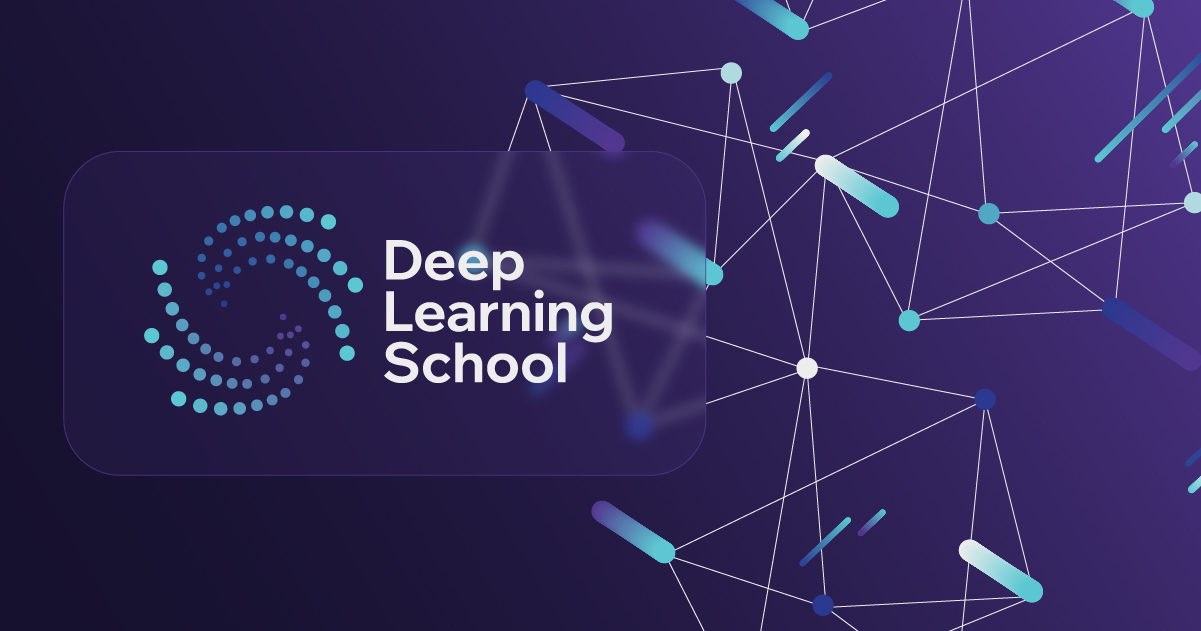

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Нейросетевая классификация текстов </b></h1>

В этом домашнем задании вам предстоит самостоятельно решить задачу классификации текстов на основе семинарского кода. Мы будем использовать датасет [ag_news](https://paperswithcode.com/dataset/ag-news). Это датасет для классификации новостей на 4 темы: "World", "Sports", "Business", "Sci/Tech".

Установим модуль datasets, чтобы нам проще было работать с данными.

In [1]:
!pip install datasets

Импорт необходимых библиотек

In [2]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import datasets

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import nltk

from collections import Counter
from typing import List
import string

import seaborn
seaborn.set(palette='summer')

In [3]:
nltk.download('punkt_tab')
nltk.download('punkt')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных
Для вашего удобства, мы привели код обработки датасета в ноутбуке. Ваша задача --- обучить модель, которая получит максимальное возможное качество на тестовой части.

In [7]:
# Загрузим датасет
dataset = datasets.load_dataset('fancyzhx/ag_news')

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Как и в семинаре, выполним следующие шаги:
* Составим словарь
* Создадим класс WordDataset
* Выделим обучающую и тестовую часть, создадим DataLoader-ы.

In [8]:
words = Counter()

for example in tqdm(dataset['train']['text']):
    # Приводим к нижнему регистру и убираем пунктуацию
    prccessed_text = example.lower().translate(
        str.maketrans('', '', string.punctuation))

    for word in word_tokenize(prccessed_text):
        words[word] += 1


vocab = set(['<unk>', '<bos>', '<eos>', '<pad>'])
counter_threshold = 25

for char, cnt in words.items():
    if cnt > counter_threshold:
        vocab.add(char)

print(f'Размер словаря: {len(vocab)}')

word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

  0%|          | 0/120000 [00:00<?, ?it/s]

Размер словаря: 11842


In [9]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        processed_text = self.data[idx]['text'].lower().translate(
            str.maketrans('', '', string.punctuation))
        tokenized_sentence = [self.bos_id]
        tokenized_sentence += [
            word2ind.get(word, self.unk_id) for word in word_tokenize(processed_text)
            ]
        tokenized_sentence += [self.eos_id]

        train_sample = {
            "text": tokenized_sentence,
            "label": self.data[idx]['label']
        }

        return train_sample

    def __len__(self) -> int:
        return len(self.data)


def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>'], max_len=256) -> torch.Tensor:
    seq_lens = [len(x['text']) for x in input_batch]
    max_seq_len = min(max(seq_lens), max_len)

    new_batch = []
    for sequence in input_batch:
        sequence['text'] = sequence['text'][:max_seq_len]
        for _ in range(max_seq_len - len(sequence['text'])):
            sequence['text'].append(pad_id)

        new_batch.append(sequence['text'])

    sequences = torch.LongTensor(new_batch).to(device)
    labels = torch.LongTensor([x['label'] for x in input_batch]).to(device)

    new_batch = {
        'input_ids': sequences,
        'label': labels
    }

    return new_batch

In [10]:
train_dataset = WordDataset(dataset['train'])

np.random.seed(42)
idx = np.random.choice(np.arange(len(dataset['test'])), 5000)
eval_dataset = WordDataset(dataset['test'].select(idx))

batch_size = 32
train_dataloader = DataLoader(
    train_dataset, shuffle=True, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, shuffle=False, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Постановка задачи
Ваша задача -- получить максимальное возможное accuracy на `eval_dataloader`. Ниже приведена функция, которую вам необходимо запустить для обученной модели, чтобы вычислить качество её работы.

In [17]:
def evaluate(model, eval_dataloader) -> float:
    """
    Calculate accuracy on validation dataloader.
    """

    predictions = []
    target = []
    with torch.no_grad():
        for batch in eval_dataloader:
            logits = model(batch['input_ids'])
            predictions.append(logits.argmax(dim=1))
            target.append(batch['label'])

    predictions = torch.cat(predictions)
    target = torch.cat(target)
    accuracy = (predictions == target).float().mean().item()

    return accuracy

## Ход работы
Оценка за домашнее задание складывается из четырех частей:
### Запуск базовой модели с семинара на новом датасете (1 балл)
На семинаре мы создали модель, которая дает на нашей задаче довольно высокое качество. Ваша цель --- обучить ее и вычислить `score`, который затем можно будет использовать в качестве бейзлайна.

В модели появится одно важное изменение: количество классов теперь равно не 2, а 4. Обратите на это внимание и найдите, что в коде создания модели нужно модифицировать, чтобы учесть это различие.

### Проведение экспериментов по улучшению модели (2 балла за каждый эксперимент)
Чтобы улучшить качество базовой модели, можно попробовать различные идеи экспериментов. Каждый выполненный эксперимент будет оцениваться в 2 балла. Для получения полного балла за этот пункт вам необходимо выполнить по крайней мере 2 эксперимента. Не расстраивайтесь, если какой-то эксперимент не дал вам прироста к качеству: он все равно зачтется, если выполнен корректно.

Вот несколько идей экспериментов:
* **Модель RNN**. Попробуйте другие нейросетевые модели --- LSTM и GRU. Мы советуем обратить внимание на [GRU](https://pytorch.org/docs/stable/generated/torch.nn.GRU.html), так как интерфейс этого класса ничем не отличается от обычной Vanilla RNN, которую мы использовали на семинаре.
* **Увеличение количества рекуррентных слоев модели**. Это можно сделать с помощью параметра `num_layers` в классе `nn.RNN`. В такой модели выходы первой RNN передаются в качестве входов второй RNN и так далее.
* **Изменение архитектуры после применения RNN**. В базовой модели используется агрегация со всех эмбеддингов. Возможно, вы захотите конкатенировать результат агрегации и эмбеддинг с последнего токена.
* **Подбор гиперпараметров и обучение до сходимости**. Возможно, для получения более высокого качества просто необходимо увеличить количество эпох обучения нейросети, а также попробовать различные гиперпараметры: размер словаря, `dropout_rate`, `hidden_dim`.

Обратите внимание, что главное правило проведения экспериментов --- необходимо совершать одно архитектурное изменение в одном эксперименте. Если вы совершите несколько изменений, то будет неясно, какое именно из изменений дало прирост к качеству.

### Получение высокого качества (3 балла)
В конце вашей работы вы должны указать, какая из моделей дала лучший результат, и вывести качество, которое дает лучшая модель, с помощью функции `evaluate`. Ваша модель будет оцениваться по метрике `accuracy` следующим образом:
* $accuracy < 0.9$ --- 0 баллов;
* $0.9 \leqslant accuracy < 0.91$ --- 1 балл;
* $0.91 \leqslant accuracy < 0.915$ --- 2 балла;
* $0.915 \leqslant accuracy$ --- 3 балла.

### Оформление отчета (2 балла)
В конце работы подробно опишите все проведенные эксперименты.
* Укажите, какие из экспериментов принесли улучшение, а какие --- нет.
* Проанализируйте графики сходимости моделей в проведенных экспериментах. Являются ли колебания качества обученных моделей существенными в зависимости от эпохи обучения, или же сходимость стабильная?
* Укажите, какая модель получилась оптимальной.

Желаем удачи!

1. Реализация baseline

In [52]:
class CharLM(nn.Module):
    def __init__(
        self,
        hidden_dim: int,
        vocab_size: int,
        num_classes: int = 4,
        aggregation_type: str = 'max',
    ):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.RNN(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)
        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))
        prediction = self.projection(self.non_lin(output))

        return prediction

In [55]:
model_baseline = CharLM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion_baseline = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer_baseline = torch.optim.Adam(model_baseline.parameters())

In [57]:
num_epochs_baseline = 5
eval_steps = len(train_dataloader) // 2

losses_type_baseline = {}
acc_type_baseline = {}

for aggregation_type in ['max', 'mean']:
    print(f"Starting training for {aggregation_type}")
    losses = []
    acc = []

    model_baseline = CharLM(
        hidden_dim=256,
        vocab_size=len(vocab),
        aggregation_type=aggregation_type,
    ).to(device)

    criterion_baseline = nn.CrossEntropyLoss(
        ignore_index=word2ind['<pad>']
    )
    optimizer_baseline = torch.optim.Adam(model_baseline.parameters())

    for epoch in range(num_epochs_baseline):
        epoch_losses = []
        model_baseline.train()

        for i, batch in enumerate(
            tqdm(train_dataloader, desc=f'Training epoch {epoch}:')
        ):
            optimizer_baseline.zero_grad()
            logits = model_baseline(batch['input_ids'])
            loss = criterion_baseline(logits, batch['label'])
            loss.backward()
            optimizer_baseline.step()

            epoch_losses.append(loss.item())

            if i % eval_steps == 0:
                model_baseline.eval()
                acc.append(evaluate(model_baseline, eval_dataloader))
                model_baseline.train()

        losses.append(sum(epoch_losses) / len(epoch_losses))

    losses_type_baseline[aggregation_type] = losses
    acc_type_baseline[aggregation_type] = acc

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

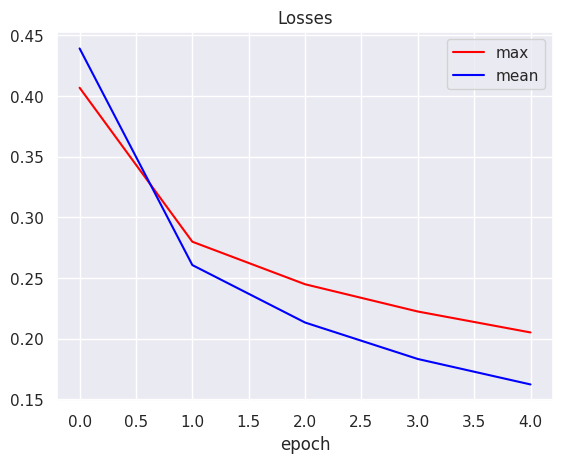

In [58]:
for (name, values), color in zip(losses_type_baseline.items(), ['red', 'blue']):
    plt.plot(np.arange(len(losses_type_baseline[name])), losses_type_baseline[name], color=color, label=name)

plt.title('Losses')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 89.86
Лучшая accuracy для подхода mean: 90.68


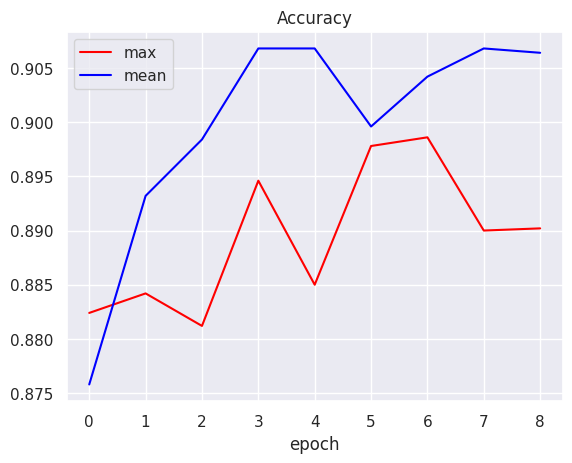

In [59]:
for (name, values), color in zip(losses_type_baseline.items(), ['red', 'blue']):
    plt.plot(np.arange(len(acc_type_baseline[name][1:])), acc_type_baseline[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type_baseline[name]) * 100):.2f}")

plt.title('Accuracy')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 89.86
Лучшая accuracy для подхода mean: 90.68
Результаты базовой модели, моя задача - улучшить их. Проведу эксперименты

Часть 2. Эксперименты

**Эксперимент 1.**
Попробовать заменить RNN на GRU.
В отличие от простой RNN, GRU использует механизмы обновления и сброса, которые управляют сохранением информации в скрытом состоянии. Это позволяет лучше учитывать зависимости между удалёнными словами и уменьшает проблему затухания градиентов при обучении. Поэтому предполагается, что замена RNN на GRU поможет модели лучше учитывать контекст новости и повысит точность классификации. При этом GRU содержит больше обучаемых параметров, а фактическое улучшение качества необходимо проверить экспериментально.
Остальные параметры остаются неизменными для точности сравнения.

In [60]:
class CharLM(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max'
        ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        # nn.GRU вместо nn.RNN
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0]  # [batch_size, hidden_dim]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1)  # [batch_size, hidden_dim]
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))  # [batch_size, hidden_dim]
        prediction = self.projection(self.non_lin(output))  # [batch_size, num_classes]

        return prediction

In [61]:
model_GRU = CharLM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion_GRU = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer_GRU = torch.optim.Adam(model_GRU.parameters())

In [62]:
num_epochs_GRU = 5
eval_steps = len(train_dataloader) // 2

losses_type_GRU = {}
acc_type_GRU = {}

for aggregation_type in ['max', 'mean']:
    print(f"Starting training for {aggregation_type}")
    losses = []
    acc = []

    model_GRU = CharLM(
        hidden_dim=256, vocab_size=len(vocab), aggregation_type=aggregation_type
    ).to(device)
    criterion_GRU = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer_GRU = torch.optim.Adam(model_GRU.parameters())

    for epoch in range(num_epochs_GRU):
        epoch_losses = []
        model_GRU.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch}:')):
            optimizer_GRU.zero_grad()
            logits = model_GRU(batch['input_ids'])
            loss = criterion_GRU(logits, batch['label'])
            loss.backward()
            optimizer_GRU.step()

            epoch_losses.append(loss.item())
            if i % eval_steps == 0:
                model_GRU.eval()
                acc.append(evaluate(model_GRU, eval_dataloader))
                model_GRU.train()

        losses.append(sum(epoch_losses) / len(epoch_losses))

    losses_type_GRU[aggregation_type] = losses
    acc_type_GRU[aggregation_type] = acc

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

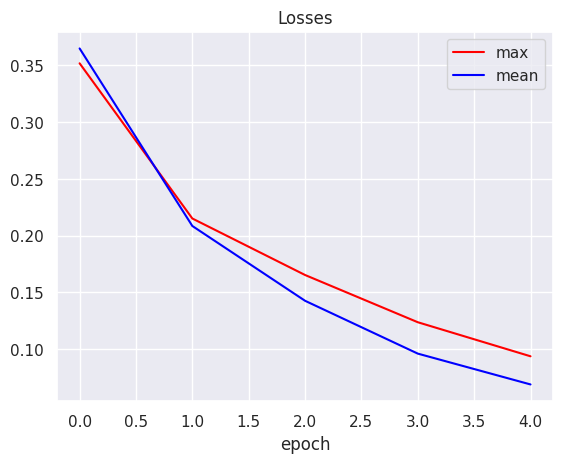

In [63]:
for (name, values), color in zip(losses_type_GRU.items(), ['red', 'blue']):
    plt.plot(np.arange(len(losses_type_GRU[name])), losses_type_GRU[name], color=color, label=name)

plt.title('Losses')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.40
Лучшая accuracy для подхода mean: 91.22


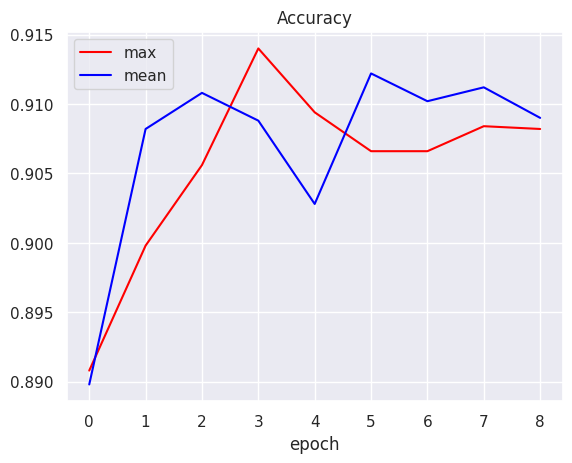

In [64]:
for (name, values), color in zip(losses_type_GRU.items(), ['red', 'blue']):
    plt.plot(np.arange(len(acc_type_GRU[name][1:])), acc_type_GRU[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type_GRU[name]) * 100):.2f}")

plt.title('Accuracy')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.40
Лучшая accuracy для подхода mean: 91.22

Данный эксперимент показал, что смена RNN на GRU улучшила результаты accuracy и уменьшила Loss. Здесь нужно учитывать, что результат изначально был очень неплохим и прирост 1.5% можно считать прогрессом. Поэтому, считаю этот эксперимент удачным, для наших данных метод подходит.

**Эксперимент 2. Увеличени числа слоёв.**

Вернёмся к RNN.
Попробую увеличить число слоёв RNN с одного до двух. Второй рекуррентный слой позволит дополнительно преобразовать контекстные представления слов и выделить более сложные признаки тематики. Предполагается увеличение accuracy по сравнению с однослойной RNN. Остальные параметры оставить такими же, сравнение с baseline.



In [65]:
class CharLM(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max'
        ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        # Изменил число слоёв num_layers=2
        self.rnn = nn.RNN(hidden_dim, hidden_dim, num_layers=2, batch_first=True,)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.1)

        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]

        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0] #[batch_size, hidden_dim]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1) #[batch_size, hidden_dim]
        else:
            raise ValueError("Invalid aggregation_type")

        output = self.dropout(self.linear(self.non_lin(output)))  # [batch_size, hidden_dim]
        prediction = self.projection(self.non_lin(output))  # [batch_size, num_classes]

        return prediction

In [66]:
model_2_layers = CharLM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion_2_layers = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer_2_layers = torch.optim.Adam(model_2_layers.parameters())

In [67]:
num_epochs_2_layers = 5
eval_steps = len(train_dataloader) // 2

losses_type_2_layers = {}
acc_type_2_layers = {}

for aggregation_type in ['max', 'mean']:
    print(f"Starting training for {aggregation_type}")
    losses = []
    acc = []

    model_2_layers = CharLM(
        hidden_dim=256, vocab_size=len(vocab), aggregation_type=aggregation_type
    ).to(device)
    criterion_2_layers = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
    optimizer_2_layers = torch.optim.Adam(model_2_layers.parameters())

    for epoch in range(num_epochs_2_layers):
        epoch_losses = []
        model_2_layers.train()
        for i, batch in enumerate(tqdm(train_dataloader, desc=f'Training epoch {epoch}:')):
            optimizer_2_layers.zero_grad()
            logits = model_2_layers(batch['input_ids'])
            loss = criterion_2_layers(logits, batch['label'])
            loss.backward()
            optimizer_2_layers.step()

            epoch_losses.append(loss.item())
            if i % eval_steps == 0:
                model_2_layers.eval()
                acc.append(evaluate(model_2_layers, eval_dataloader))
                model_2_layers.train()

        losses.append(sum(epoch_losses) / len(epoch_losses))

    losses_type_2_layers[aggregation_type] = losses
    acc_type_2_layers[aggregation_type] = acc

Starting training for max


Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

...

Training epoch 0::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 1::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 2::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 3::   0%|          | 0/3750 [00:00<?, ?it/s]

Training epoch 4::   0%|          | 0/3750 [00:00<?, ?it/s]

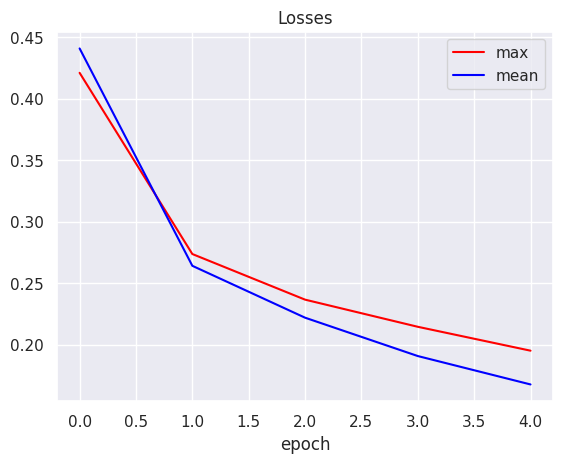

In [68]:
for (name, values), color in zip(losses_type_2_layers.items(), ['red', 'blue']):
    plt.plot(np.arange(len(losses_type_2_layers[name])), losses_type_2_layers[name], color=color, label=name)

plt.title('Losses')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.28
Лучшая accuracy для подхода mean: 90.54


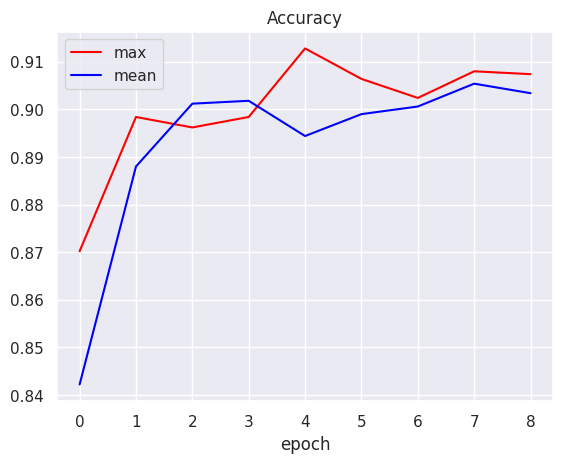

In [69]:
for (name, values), color in zip(losses_type_2_layers.items(), ['red', 'blue']):
    plt.plot(np.arange(len(acc_type_2_layers[name][1:])), acc_type_2_layers[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type_2_layers[name]) * 100):.2f}")

plt.title('Accuracy')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.28
Лучшая accuracy для подхода mean: 90.54
Метод тоже показал неплохой прирост, однако прошлый был эффективнее

**Эксепримент 3. Изменение количества эпох и размера эмбеддингов**

Увеличение размерности представлений позволит модели сохранять больше признаков текста, а дополнительные эпохи дадут больше времени для их обучения. Предполагается рост accuracy, однако увеличивается риск переобучения.
Проверять я буду на модели с GRU, так как у нее были лучшие результаты.
Так как растет риск переобучения, я добавил отображение текущго loss и acc после каждой эпохи. Таким образом, если loss уменьшается, а качество acc падает,значит модель начинает переобучаться.
Эпох стало 15, размер эмбеддингов стал 512, outdrop поввысил до 0.3 для уменьшения риска переобучения

In [70]:
class CharLM(nn.Module):
    def __init__(
        self, hidden_dim: int, vocab_size: int, num_classes: int = 4,
        aggregation_type: str = 'max'
        ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        # nn.GRU вместо nn.RNN
        self.rnn = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, num_classes)
        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p=0.3)
        self.aggregation_type = aggregation_type

    def forward(self, input_batch) -> torch.Tensor:
        embeddings = self.embedding(input_batch)  # [batch_size, seq_len, hidden_dim]
        output, _ = self.rnn(embeddings)  # [batch_size, seq_len, hidden_dim]
        if self.aggregation_type == 'max':
            output = output.max(dim=1)[0] #[batch_size, hidden_dim]
        elif self.aggregation_type == 'mean':
            output = output.mean(dim=1) #[batch_size, hidden_dim]
        else:
            raise ValueError("Invalid aggregation_type")
        output = self.dropout(self.linear(self.non_lin(output)))  # [batch_size, hidden_dim]
        prediction = self.projection(self.non_lin(output))  # [batch_size, num_classes]
        return prediction

In [71]:
model_GRU_512_003 = CharLM(hidden_dim=256, vocab_size=len(vocab)).to(device)
criterion_GRU_512_003 = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer_GRU_512_003 = torch.optim.Adam(model_GRU_512_003.parameters())

In [72]:
num_epochs_GRU_512_003 = 15
losses_type_GRU_512_003 = {}
eval_losses_type_GRU_512_003 = {}
acc_type_GRU_512_003 = {}

for aggregation_type in ['max', 'mean']:
    print(f"Starting training for {aggregation_type}")
    losses = []
    eval_losses = []
    acc = []

    model_GRU_512_003 = CharLM(
        hidden_dim=512,
        vocab_size=len(vocab),
        num_classes=4,
        aggregation_type=aggregation_type
    ).to(device)

    criterion_GRU_512_003 = nn.CrossEntropyLoss()
    optimizer_GRU_512_003 = torch.optim.Adam(model_GRU_512_003.parameters())

    for epoch in range(num_epochs_GRU_512_003):
        model_GRU_512_003.train()
        train_loss_sum = 0.0
        train_count = 0

        progress = tqdm(
            train_dataloader,
            desc=f'Training epoch {epoch + 1}/{num_epochs_GRU_512_003}'
        )

        for batch in progress:
            optimizer_GRU_512_003.zero_grad()
            logits = model_GRU_512_003(batch['input_ids'])
            loss = criterion_GRU_512_003(logits, batch['label'])
            loss.backward()
            optimizer_GRU_512_003.step()

            n = batch['label'].size(0)
            train_loss_sum += loss.item() * n
            train_count += n

            progress.set_postfix(
                loss=f'{train_loss_sum / train_count:.4f}'
            )

        losses.append(train_loss_sum / train_count)

        model_GRU_512_003.eval()
        eval_loss_sum = 0.0
        eval_count = 0
        correct = 0

        with torch.no_grad():
            for batch in eval_dataloader:
                logits = model_GRU_512_003(batch['input_ids'])
                loss = criterion_GRU_512_003(logits, batch['label'])

                n = batch['label'].size(0)
                eval_loss_sum += loss.item() * n
                eval_count += n
                correct += (
                    logits.argmax(dim=1) == batch['label']
                ).sum().item()

        eval_losses.append(eval_loss_sum / eval_count)
        acc.append(correct / eval_count)

        print(
            f'Epoch {epoch + 1}/{num_epochs_GRU_512_003} | '
            f'Train loss: {losses[-1]:.4f} | '
            f'Eval loss: {eval_losses[-1]:.4f} | '
            f'Accuracy: {acc[-1]:.4f}'
        )

    losses_type_GRU_512_003[aggregation_type] = losses
    eval_losses_type_GRU_512_003[aggregation_type] = eval_losses
    acc_type_GRU_512_003[aggregation_type] = acc

Starting training for max


Training epoch 1/15:   0%|          | 0/3750 [00:00<?, ?it/s]

Epoch 1/15 | Train loss: 0.3356 | Eval loss: 0.3135 | Accuracy: 0.9060


Training epoch 2/15:   0%|          | 0/3750 [00:00<?, ?it/s]

Epoch 2/15 | Train loss: 0.2148 | Eval loss: 0.2954 | Accuracy: 0.9148


...

Epoch 13/15 | Train loss: 0.0702 | Eval loss: 0.5850 | Accuracy: 0.8970


Training epoch 14/15:   0%|          | 0/3750 [00:00<?, ?it/s]

Epoch 14/15 | Train loss: 0.0751 | Eval loss: 0.6159 | Accuracy: 0.8936


Training epoch 15/15:   0%|          | 0/3750 [00:00<?, ?it/s]

Epoch 15/15 | Train loss: 0.0840 | Eval loss: 0.5206 | Accuracy: 0.8972


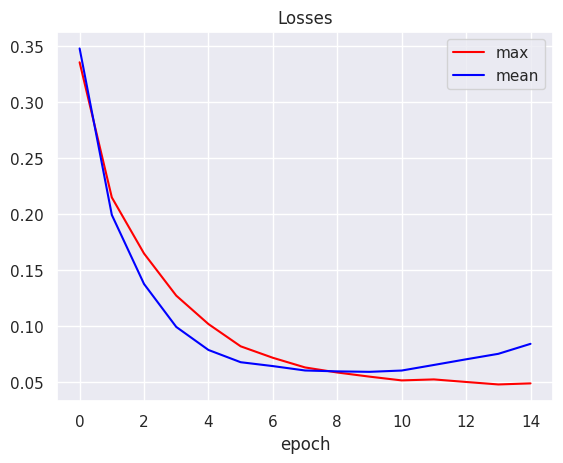

In [73]:
for (name, values), color in zip(losses_type_GRU_512_003.items(), ['red', 'blue']):
    plt.plot(np.arange(len(losses_type_GRU_512_003[name])), losses_type_GRU_512_003[name], color=color, label=name)

plt.title('Losses')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.48
Лучшая accuracy для подхода mean: 91.12


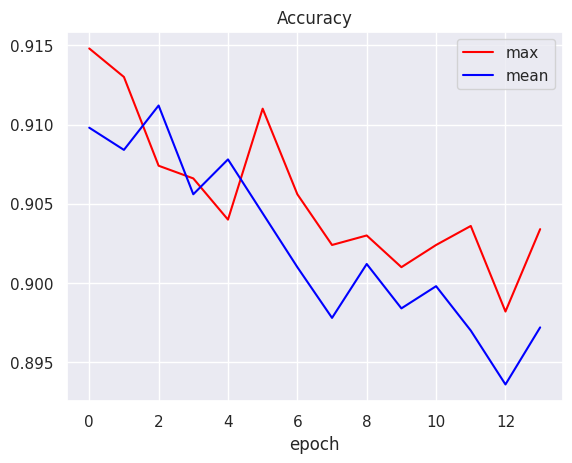

In [74]:
for (name, values), color in zip(losses_type_GRU_512_003.items(), ['red', 'blue']):
    plt.plot(np.arange(len(acc_type_GRU_512_003[name][1:])), acc_type_GRU_512_003[name][1:], color=color, label=name)
    print(f"Лучшая accuracy для подхода {name}: {(max(acc_type_GRU_512_003[name]) * 100):.2f}")

plt.title('Accuracy')
plt.xlabel("epoch")
plt.legend()
plt.show()

Лучшая accuracy для подхода max: 91.48
Лучшая accuracy для подхода mean: 91.12
Однако, видно переобучение (loss снижается, acc тоже).

In [75]:
model_baseline.eval()
score = evaluate(model_baseline, eval_dataloader)
print(f'Accuracy: {score:.4f} ({score:.2%})')

Accuracy: 0.9052 (90.52%)


In [76]:
model_GRU.eval()
score = evaluate(model_GRU, eval_dataloader)
print(f'Accuracy: {score:.4f} ({score:.2%})')

Accuracy: 0.9050 (90.50%)


In [77]:
model_2_layers.eval()
score = evaluate(model_2_layers, eval_dataloader)
print(f'Accuracy: {score:.4f} ({score:.2%})')

Accuracy: 0.9046 (90.46%)


In [78]:
model_GRU_512_003.eval()
score = evaluate(model_GRU_512_003, eval_dataloader)
print(f'Accuracy: {score:.4f} ({score:.2%})')

Accuracy: 0.8972 (89.72%)
